# Instance Reduction Analysis

This notebook presents the evaluation of **Instance Reduction Techniques** applied to:
1. **Best kNN (Static - Never Retain)**: Measuring the pure impact of training set reduction on instance-based classification.
2. **Best kNN (Dynamic - Always Retain)**: Measuring interaction between reduction and incremental learning.
3. **Best SVM**: Trained exclusively on the reduced subset.
4. **Best Random Forest**: Trained exclusively on the reduced subset.

### Reduction Algorithms Evaluated
- **None**: Baseline full training set (100% storage).
- **GCNN**: Generalized Condensed Nearest Neighbor (order-independent condensation).
- **RNGE**: Relative Neighborhood Graph Edition (graph-based boundary edition/cleaning).
- **DEL**: Decremental Reduction by Success Rates (sorting by margin goodness and pruning non-critical prototypes).

### Statistical Protocol (Demšar, 2006)
- Evaluated across $N=10$ folds for both **Soybean** and **Hypothyroid**.
- All data dynamically loaded from `results/reduction/`.
- **Friedman Omnibus Test** per algorithm across the 4 reduction methods.
- Critical Difference (CD) diagrams per algorithm.
- **Pairwise Wilcoxon Signed-Rank Tests** comparing each reduction algorithm against the unreduced baseline (`none`).


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import importlib

# Setup paths dynamically
current_dir = Path().resolve()
if (current_dir / "Work2").exists():
    ROOT = current_dir / "Work2"
elif current_dir.name == "analysis":
    ROOT = current_dir.parent
else:
    ROOT = current_dir

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import analysis.statistical_utils
importlib.reload(analysis.statistical_utils)

from analysis.statistical_utils import (
    load_fold_results,
    load_summary_results,
    RESULTS_DIR,
)

REDUCTION_DIR = RESULTS_DIR / "reduction"
print(f"Reading reduction outputs dynamically from: {REDUCTION_DIR}")


Reading reduction outputs dynamically from: C:\Users\Administrator\IML-Lab-2026\Work2\results\reduction


## 1. Soybean Dataset: Instance Reduction Impact


In [2]:
# Dynamically load summary and fold results for Soybean
df_red_soy_summary = load_summary_results("reduction", "soybean")
print("=== Soybean: Summary of Reduction Methods across Classifiers ===")
display(df_red_soy_summary[["algorithm", "reduction_method", "accuracy", "accuracy_std", 
                            "f1_macro", "storage_pct", "reduction_time", "prediction_time"]])


=== Soybean: Summary of Reduction Methods across Classifiers ===


,algorithm,reduction_method,accuracy,accuracy_std,f1_macro,storage_pct,reduction_time,prediction_time
0,Best SVM,none,0.941780,0.019646,0.958245,100.000000,0.000055,0.003853
1,Best RF,none,0.940491,0.024176,0.967683,100.000000,0.000055,0.031603
2,Best kNN (AR),none,0.926139,0.026553,0.943376,111.114824,0.000055,0.051452
3,Best SVM,rnge,0.925974,0.020065,0.950423,89.180662,0.341260,0.003786
4,Best RF,del,0.922900,0.025281,0.953429,22.092244,8.319532,0.030684
5,Best RF,rnge,0.922313,0.019476,0.942094,89.180662,0.341260,0.030624
6,Best kNN (NR),none,0.921515,0.026268,0.947234,100.000000,0.000055,0.028180
7,Best kNN (AR),rnge,0.913242,0.028479,0.939895,100.295486,0.541591,0.046292
8,Best kNN (NR),rnge,0.894318,0.035603,0.919380,89.180662,0.341260,0.023974
9,Best RF,gcnn,0.882940,0.050668,0.900391,24.791620,0.162523,0.031159


### 1.1 Soybean: Pairwise Wilcoxon Tests vs 'None' Baseline


In [3]:
df_wilc_soy = pd.read_csv(REDUCTION_DIR / "soybean_stats_wilcoxon_vs_none.csv")
print("=== Soybean: Pairwise Wilcoxon Signed-Rank Tests (Reduction vs 'None' Baseline) ===")
display(df_wilc_soy[["algorithm", "reduction_method", "mean_a", "mean_b", "mean_diff", "p_value", "significant"]])


=== Soybean: Pairwise Wilcoxon Signed-Rank Tests (Reduction vs 'None' Baseline) ===


,algorithm,reduction_method,mean_a,mean_b,mean_diff,p_value,significant
0,Best kNN (NR),gcnn,0.761204,0.921515,-0.160311,0.001953,True
1,Best kNN (NR),rnge,0.894318,0.921515,-0.027197,0.007812,True
2,Best kNN (NR),del,0.878555,0.921515,-0.042959,0.007812,True
3,Best kNN (AR),gcnn,0.857057,0.926139,-0.069082,0.001953,True
4,Best kNN (AR),rnge,0.913242,0.926139,-0.012897,0.062500,False
5,Best kNN (AR),del,0.875688,0.926139,-0.050451,0.001953,True
6,Best SVM,gcnn,0.630755,0.941780,-0.311025,0.001953,True
7,Best SVM,rnge,0.925974,0.941780,-0.015807,0.007812,True
8,Best SVM,del,0.860522,0.941780,-0.081259,0.001953,True
9,Best RF,gcnn,0.882940,0.940491,-0.057550,0.009766,True


### 1.2 Soybean: Friedman Rankings & Critical Difference (CD) Diagrams per Classifier


=== Soybean Friedman Rankings across Reduction Methods: Best kNN (NR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.2,0.921515,0.026268,0.0,True,True
1,rnge,2.2,0.894318,0.035603,1.0,True,True
2,del,2.6,0.878555,0.026794,1.4,True,False
3,gcnn,4.0,0.761204,0.055522,2.8,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best kNN (AR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.25,0.926139,0.026553,0.00,True,True
1,rnge,1.90,0.913242,0.028479,0.65,True,True
2,del,3.30,0.875688,0.028923,2.05,False,False
3,gcnn,3.55,0.857057,0.037567,2.30,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best SVM ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.1,0.941780,0.019646,0.0,True,True
1,rnge,2.0,0.925974,0.020065,0.9,True,True
2,del,2.9,0.860522,0.039577,1.8,False,False
3,gcnn,4.0,0.630755,0.078454,2.9,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best RF ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.60,0.940491,0.024176,0.00,True,True
1,rnge,2.55,0.922313,0.019476,0.95,True,True
2,del,2.55,0.922900,0.025281,0.95,True,True
3,gcnn,3.30,0.882940,0.050668,1.70,False,False


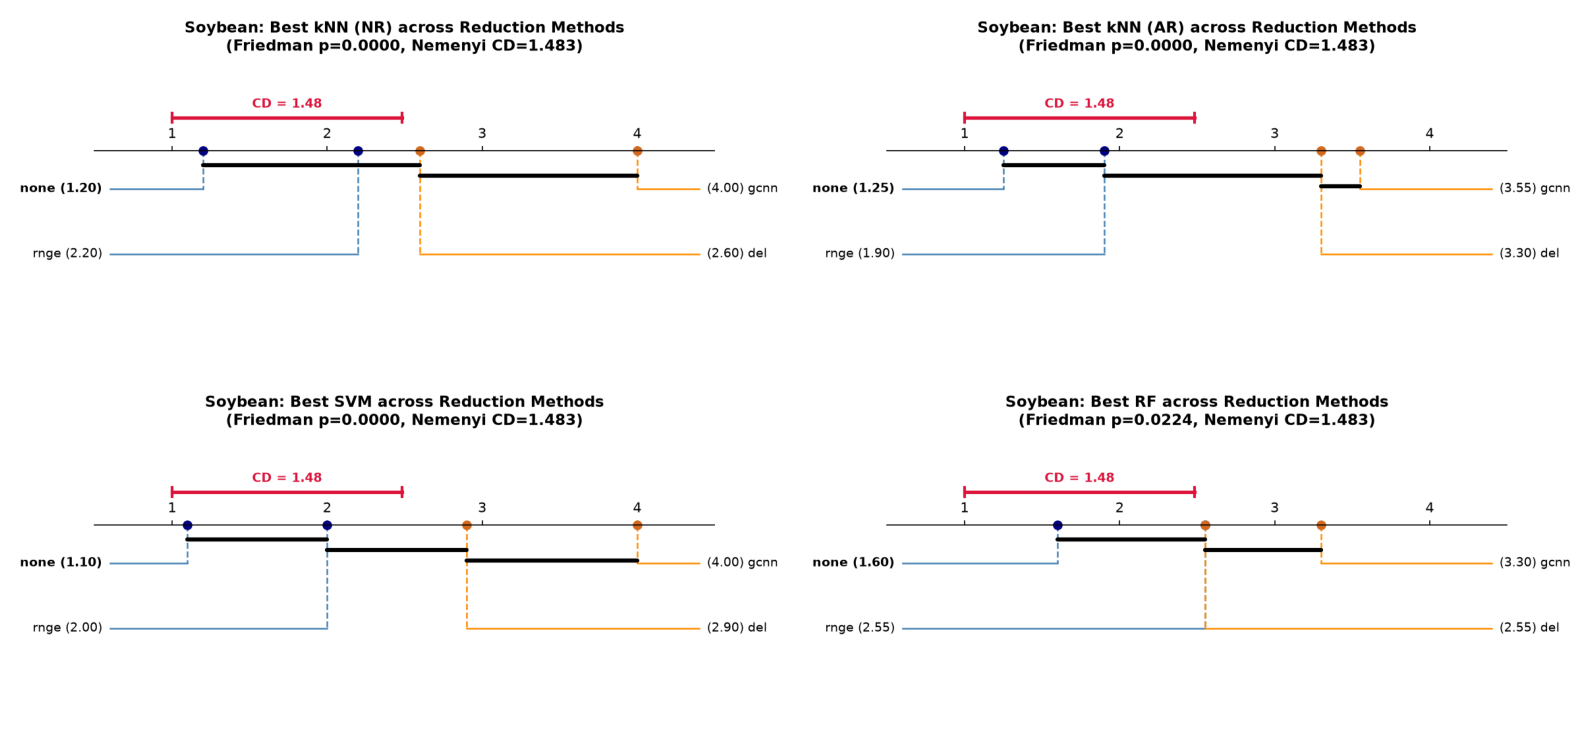

In [4]:
for algo_key, algo_label in [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]:
    df_fr_soy = pd.read_csv(REDUCTION_DIR / f'soybean_stats_{algo_key}_reduction.csv')
    print(f'=== Soybean Friedman Rankings across Reduction Methods: {algo_label} ===')
    display(df_fr_soy)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, (algo_key, algo_label) in zip(axes.flat, [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]):
    img = plt.imread(REDUCTION_DIR / f'soybean_cd_{algo_key}_reduction.png')
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.show()


### 1.2 Soybean: Friedman Rankings & Critical Difference (CD) Diagrams per Classifier


=== Soybean Friedman Rankings across Reduction Methods: Best kNN (NR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.2,0.921515,0.026268,0.0,True,True
1,rnge,2.2,0.894318,0.035603,1.0,True,True
2,del,2.6,0.878555,0.026794,1.4,True,False
3,gcnn,4.0,0.761204,0.055522,2.8,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best kNN (AR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.25,0.926139,0.026553,0.00,True,True
1,rnge,1.90,0.913242,0.028479,0.65,True,True
2,del,3.30,0.875688,0.028923,2.05,False,False
3,gcnn,3.55,0.857057,0.037567,2.30,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best SVM ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.1,0.941780,0.019646,0.0,True,True
1,rnge,2.0,0.925974,0.020065,0.9,True,True
2,del,2.9,0.860522,0.039577,1.8,False,False
3,gcnn,4.0,0.630755,0.078454,2.9,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best RF ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.60,0.940491,0.024176,0.00,True,True
1,rnge,2.55,0.922313,0.019476,0.95,True,True
2,del,2.55,0.922900,0.025281,0.95,True,True
3,gcnn,3.30,0.882940,0.050668,1.70,False,False


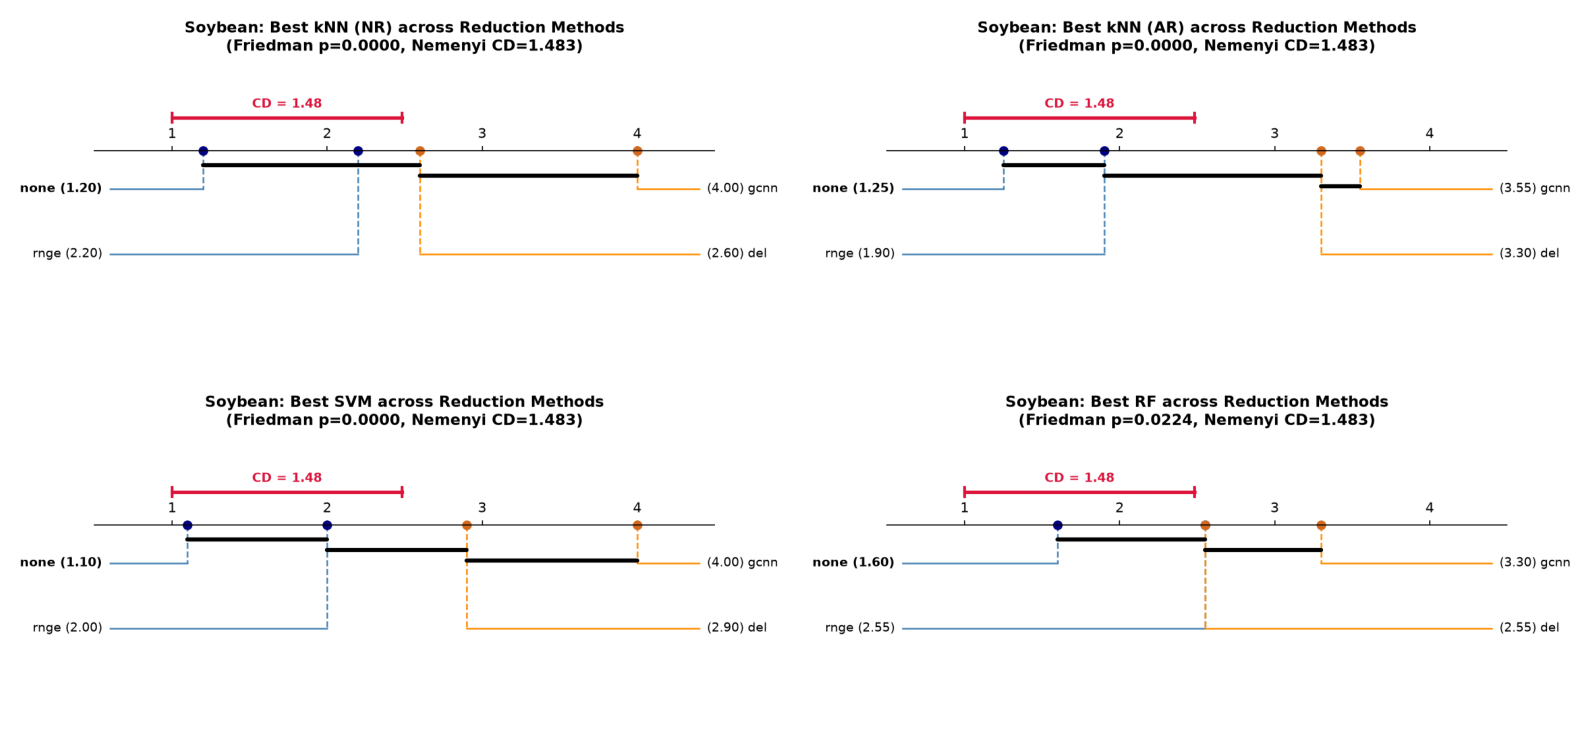

In [5]:
for algo_key, algo_label in [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]:
    df_fr_soy = pd.read_csv(REDUCTION_DIR / f'soybean_stats_{algo_key}_reduction.csv')
    print(f'=== Soybean Friedman Rankings across Reduction Methods: {algo_label} ===')
    display(df_fr_soy)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, (algo_key, algo_label) in zip(axes.flat, [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]):
    img = plt.imread(REDUCTION_DIR / f'soybean_cd_{algo_key}_reduction.png')
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.show()


### 1.2 Soybean: Friedman Rankings & Critical Difference (CD) Diagrams per Classifier


=== Soybean Friedman Rankings across Reduction Methods: Best kNN (NR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.2,0.921515,0.026268,0.0,True,True
1,rnge,2.2,0.894318,0.035603,1.0,True,True
2,del,2.6,0.878555,0.026794,1.4,True,False
3,gcnn,4.0,0.761204,0.055522,2.8,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best kNN (AR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.25,0.926139,0.026553,0.00,True,True
1,rnge,1.90,0.913242,0.028479,0.65,True,True
2,del,3.30,0.875688,0.028923,2.05,False,False
3,gcnn,3.55,0.857057,0.037567,2.30,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best SVM ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.1,0.941780,0.019646,0.0,True,True
1,rnge,2.0,0.925974,0.020065,0.9,True,True
2,del,2.9,0.860522,0.039577,1.8,False,False
3,gcnn,4.0,0.630755,0.078454,2.9,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best RF ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.60,0.940491,0.024176,0.00,True,True
1,rnge,2.55,0.922313,0.019476,0.95,True,True
2,del,2.55,0.922900,0.025281,0.95,True,True
3,gcnn,3.30,0.882940,0.050668,1.70,False,False


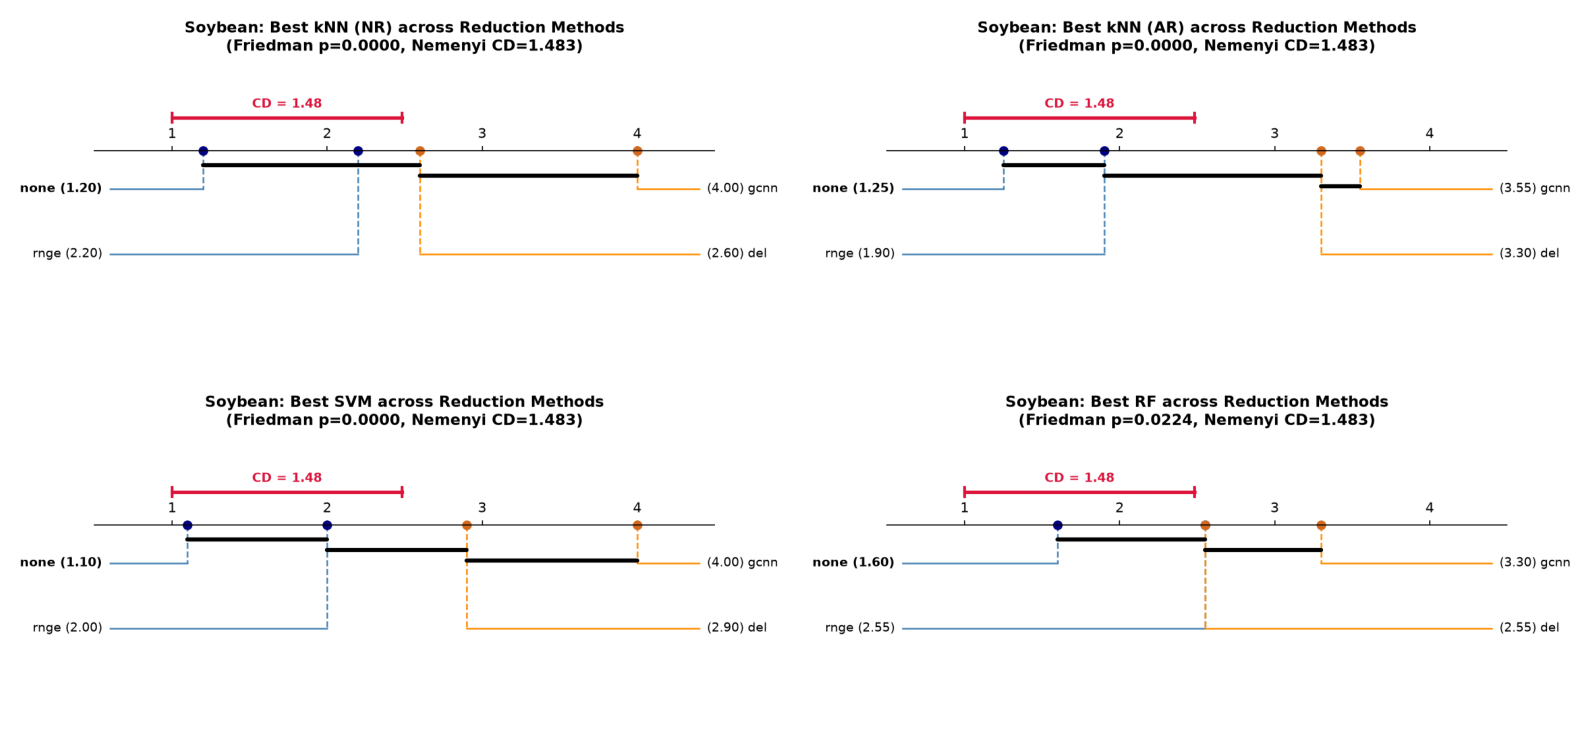

In [6]:
for algo_key, algo_label in [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]:
    df_fr_soy = pd.read_csv(REDUCTION_DIR / f'soybean_stats_{algo_key}_reduction.csv')
    print(f'=== Soybean Friedman Rankings across Reduction Methods: {algo_label} ===')
    display(df_fr_soy)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, (algo_key, algo_label) in zip(axes.flat, [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]):
    img = plt.imread(REDUCTION_DIR / f'soybean_cd_{algo_key}_reduction.png')
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.show()


### 1.2 Soybean: Friedman Rankings & Critical Difference (CD) Diagrams per Classifier


=== Soybean Friedman Rankings across Reduction Methods: Best kNN (NR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.2,0.921515,0.026268,0.0,True,True
1,rnge,2.2,0.894318,0.035603,1.0,True,True
2,del,2.6,0.878555,0.026794,1.4,True,False
3,gcnn,4.0,0.761204,0.055522,2.8,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best kNN (AR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.25,0.926139,0.026553,0.00,True,True
1,rnge,1.90,0.913242,0.028479,0.65,True,True
2,del,3.30,0.875688,0.028923,2.05,False,False
3,gcnn,3.55,0.857057,0.037567,2.30,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best SVM ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.1,0.941780,0.019646,0.0,True,True
1,rnge,2.0,0.925974,0.020065,0.9,True,True
2,del,2.9,0.860522,0.039577,1.8,False,False
3,gcnn,4.0,0.630755,0.078454,2.9,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best RF ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.60,0.940491,0.024176,0.00,True,True
1,rnge,2.55,0.922313,0.019476,0.95,True,True
2,del,2.55,0.922900,0.025281,0.95,True,True
3,gcnn,3.30,0.882940,0.050668,1.70,False,False


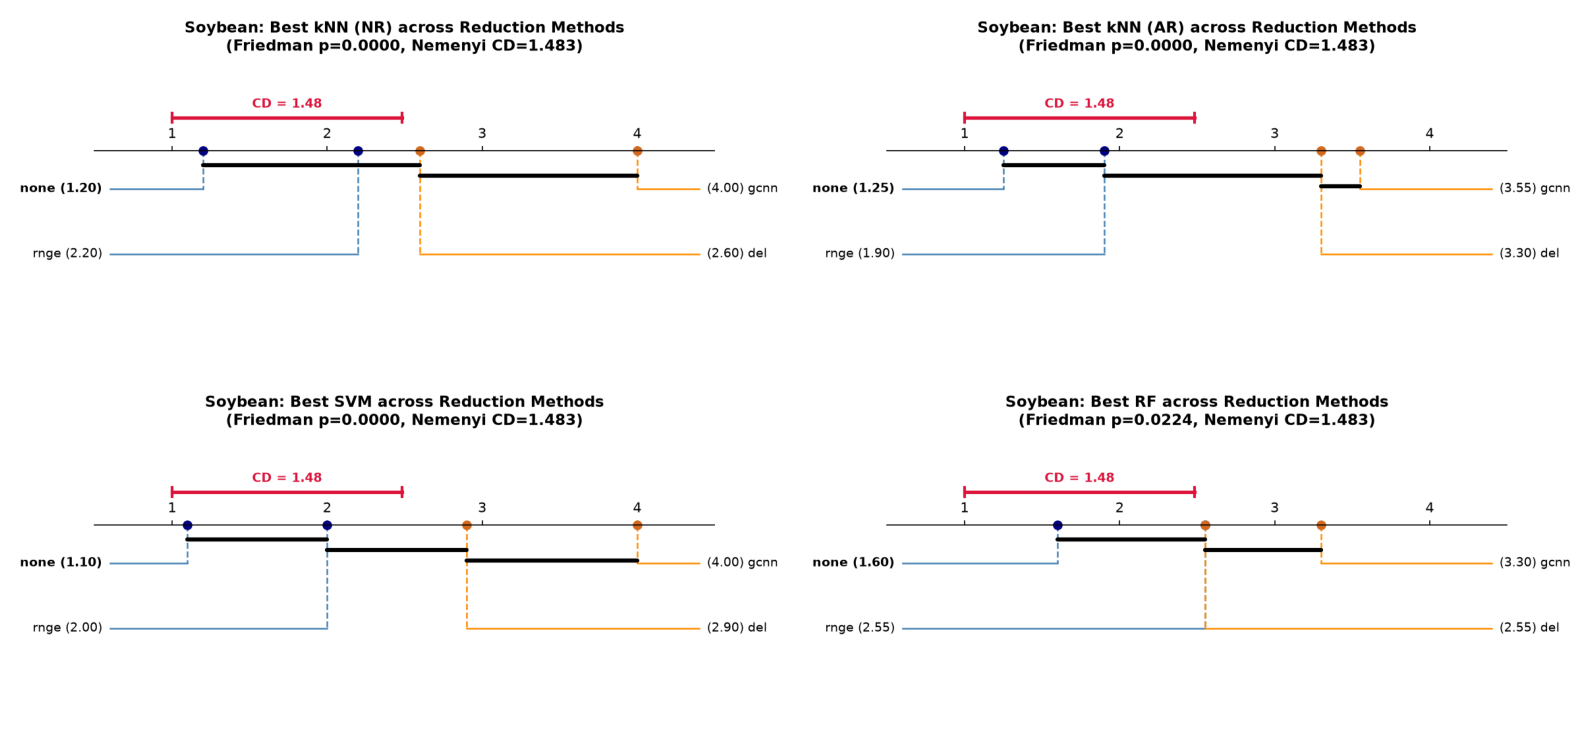

In [7]:
for algo_key, algo_label in [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]:
    df_fr_soy = pd.read_csv(REDUCTION_DIR / f'soybean_stats_{algo_key}_reduction.csv')
    print(f'=== Soybean Friedman Rankings across Reduction Methods: {algo_label} ===')
    display(df_fr_soy)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, (algo_key, algo_label) in zip(axes.flat, [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]):
    img = plt.imread(REDUCTION_DIR / f'soybean_cd_{algo_key}_reduction.png')
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.show()


### 1.2 Soybean: Friedman Rankings & Critical Difference (CD) Diagrams per Classifier


=== Soybean Friedman Rankings across Reduction Methods: Best kNN (NR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.2,0.921515,0.026268,0.0,True,True
1,rnge,2.2,0.894318,0.035603,1.0,True,True
2,del,2.6,0.878555,0.026794,1.4,True,False
3,gcnn,4.0,0.761204,0.055522,2.8,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best kNN (AR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.25,0.926139,0.026553,0.00,True,True
1,rnge,1.90,0.913242,0.028479,0.65,True,True
2,del,3.30,0.875688,0.028923,2.05,False,False
3,gcnn,3.55,0.857057,0.037567,2.30,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best SVM ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.1,0.941780,0.019646,0.0,True,True
1,rnge,2.0,0.925974,0.020065,0.9,True,True
2,del,2.9,0.860522,0.039577,1.8,False,False
3,gcnn,4.0,0.630755,0.078454,2.9,False,False


=== Soybean Friedman Rankings across Reduction Methods: Best RF ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.60,0.940491,0.024176,0.00,True,True
1,rnge,2.55,0.922313,0.019476,0.95,True,True
2,del,2.55,0.922900,0.025281,0.95,True,True
3,gcnn,3.30,0.882940,0.050668,1.70,False,False


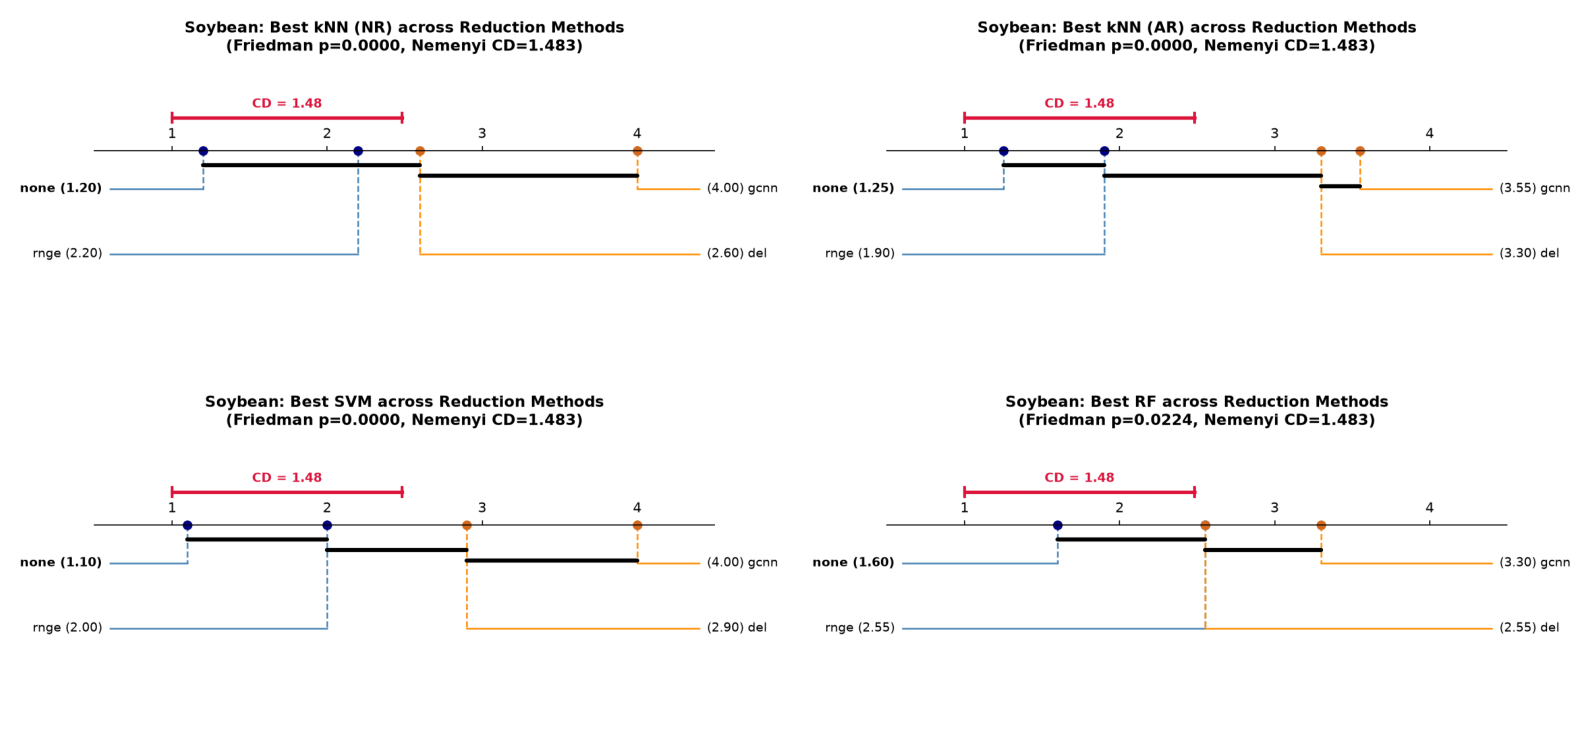

In [8]:
for algo_key, algo_label in [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]:
    df_fr_soy = pd.read_csv(REDUCTION_DIR / f'soybean_stats_{algo_key}_reduction.csv')
    print(f'=== Soybean Friedman Rankings across Reduction Methods: {algo_label} ===')
    display(df_fr_soy)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, (algo_key, algo_label) in zip(axes.flat, [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]):
    img = plt.imread(REDUCTION_DIR / f'soybean_cd_{algo_key}_reduction.png')
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.show()


## 2. Hypothyroid Dataset: Instance Reduction Impact


In [9]:
# Dynamically load summary and fold results for Hypothyroid
df_red_hypo_summary = load_summary_results("reduction", "hypothyroid")
print("=== Hypothyroid: Summary of Reduction Methods across Classifiers ===")
display(df_red_hypo_summary[["algorithm", "reduction_method", "accuracy", "accuracy_std", 
                             "f1_macro", "storage_pct", "reduction_time", "prediction_time"]])


=== Hypothyroid: Summary of Reduction Methods across Classifiers ===


,algorithm,reduction_method,accuracy,accuracy_std,f1_macro,storage_pct,reduction_time,prediction_time
0,Best RF,none,0.995763,0.003103,0.925172,100.000000,0.000037,0.044681
1,Best RF,gcnn,0.993374,0.003592,0.912844,10.277433,5.885069,0.042246
2,Best RF,del,0.992320,0.005054,0.911676,7.632235,62.424317,0.043699
3,Best RF,rnge,0.988076,0.006509,0.877094,97.263490,48.837696,0.043154
4,Best SVM,none,0.975100,0.010715,0.791936,100.000000,0.000037,0.002407
5,Best SVM,rnge,0.971918,0.011209,0.811271,97.263490,48.837696,0.001734
6,Best kNN (AR),del,0.969524,0.007372,0.791379,18.743355,62.424317,0.284713
7,Best kNN (NR),gcnn,0.968454,0.007109,0.775769,10.277433,5.885069,0.140380
8,Best kNN (AR),gcnn,0.967664,0.006673,0.771786,21.388553,5.885069,0.297082
9,Best kNN (NR),del,0.966605,0.008270,0.792931,7.632235,62.424317,0.135925


### 2.1 Hypothyroid: Pairwise Wilcoxon Tests vs 'None' Baseline


In [10]:
df_wilc_hypo = pd.read_csv(REDUCTION_DIR / "hypothyroid_stats_wilcoxon_vs_none.csv")
print("=== Hypothyroid: Pairwise Wilcoxon Signed-Rank Tests (Reduction vs 'None' Baseline) ===")
display(df_wilc_hypo[["algorithm", "reduction_method", "mean_a", "mean_b", "mean_diff", "p_value", "significant"]])


=== Hypothyroid: Pairwise Wilcoxon Signed-Rank Tests (Reduction vs 'None' Baseline) ===


,algorithm,reduction_method,mean_a,mean_b,mean_diff,p_value,significant
0,Best kNN (NR),gcnn,0.968454,0.966078,0.002376,0.539062,False
1,Best kNN (NR),rnge,0.960772,0.966078,-0.005306,0.015625,True
2,Best kNN (NR),del,0.966605,0.966078,0.000526,0.882812,False
3,Best kNN (AR),gcnn,0.967664,0.966343,0.001321,0.714844,False
4,Best kNN (AR),rnge,0.960773,0.966343,-0.005570,0.015625,True
5,Best kNN (AR),del,0.969524,0.966343,0.003181,0.226562,False
6,Best SVM,gcnn,0.934537,0.975100,-0.040563,0.001953,True
7,Best SVM,rnge,0.971918,0.975100,-0.003182,0.175781,False
8,Best SVM,del,0.907218,0.975100,-0.067882,0.001953,True
9,Best RF,gcnn,0.993374,0.995763,-0.002389,0.062500,False


### 2.2 Hypothyroid: Friedman Rankings & Critical Difference (CD) Diagrams per Classifier


=== Hypothyroid Friedman Rankings across Reduction Methods: Best kNN (NR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,gcnn,1.8,0.968454,0.007109,0.0,True,True
1,none,2.1,0.966078,0.010843,0.3,True,True
2,del,2.5,0.966605,0.008270,0.7,True,True
3,rnge,3.6,0.960772,0.009386,1.8,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best kNN (AR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,del,2.00,0.969524,0.007372,0.00,True,True
1,gcnn,2.15,0.967664,0.006673,0.15,True,True
2,none,2.30,0.966343,0.010646,0.30,True,True
3,rnge,3.55,0.960773,0.009629,1.55,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best SVM ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.35,0.975100,0.010715,0.0,True,True
1,rnge,1.65,0.971918,0.011209,0.3,True,True
2,gcnn,3.15,0.934537,0.018204,1.8,False,False
3,del,3.85,0.907218,0.025199,2.5,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best RF ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.30,0.995763,0.003103,0.00,True,True
1,gcnn,2.30,0.993374,0.003592,1.00,True,True
2,del,2.65,0.992320,0.005054,1.35,True,True
3,rnge,3.75,0.988076,0.006509,2.45,False,False


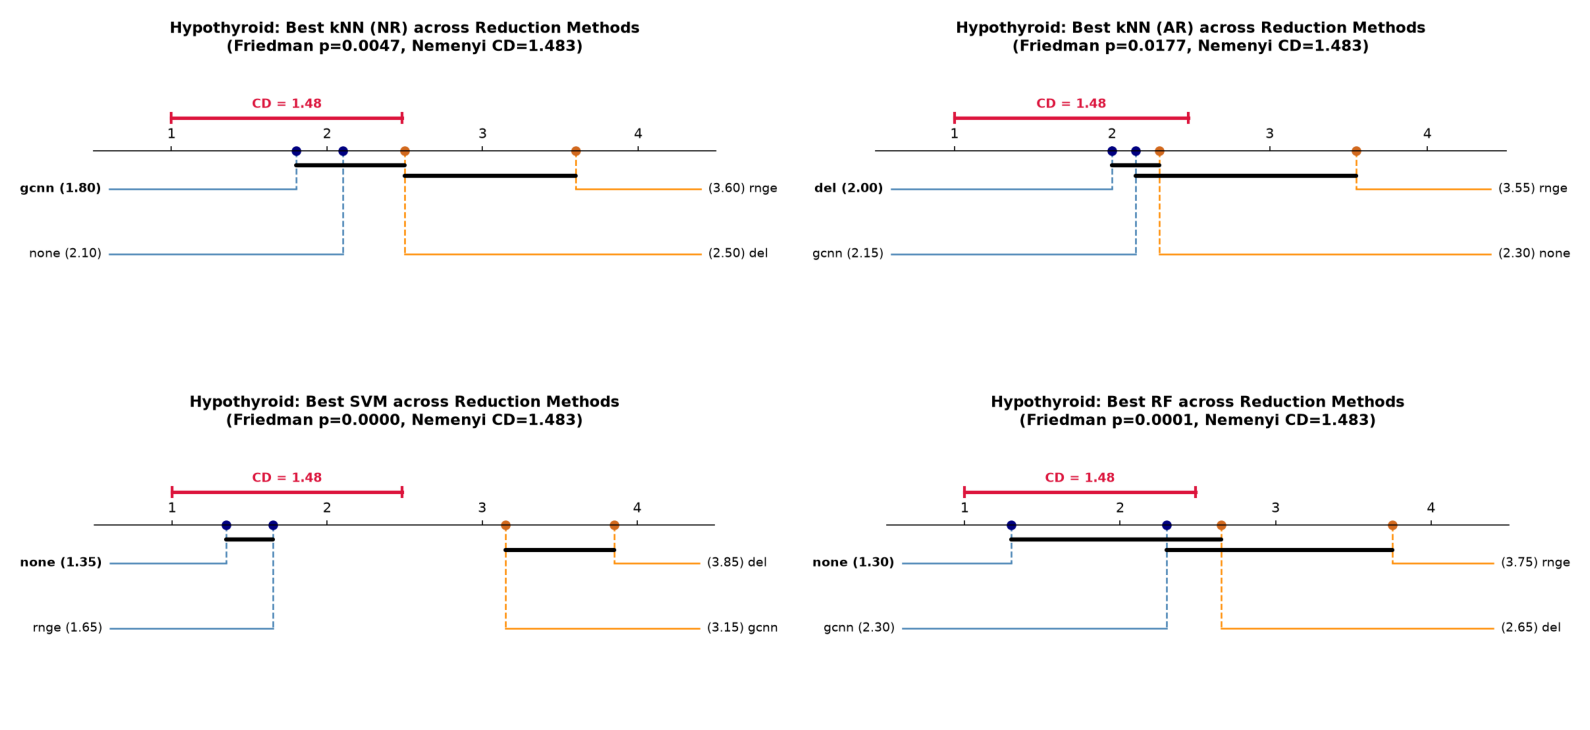

In [11]:
for algo_key, algo_label in [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]:
    df_fr_hypo = pd.read_csv(REDUCTION_DIR / f'hypothyroid_stats_{algo_key}_reduction.csv')
    print(f'=== Hypothyroid Friedman Rankings across Reduction Methods: {algo_label} ===')
    display(df_fr_hypo)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, (algo_key, algo_label) in zip(axes.flat, [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]):
    img = plt.imread(REDUCTION_DIR / f'hypothyroid_cd_{algo_key}_reduction.png')
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.show()


### 2.2 Hypothyroid: Friedman Rankings & Critical Difference (CD) Diagrams per Classifier


=== Hypothyroid Friedman Rankings across Reduction Methods: Best kNN (NR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,gcnn,1.8,0.968454,0.007109,0.0,True,True
1,none,2.1,0.966078,0.010843,0.3,True,True
2,del,2.5,0.966605,0.008270,0.7,True,True
3,rnge,3.6,0.960772,0.009386,1.8,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best kNN (AR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,del,2.00,0.969524,0.007372,0.00,True,True
1,gcnn,2.15,0.967664,0.006673,0.15,True,True
2,none,2.30,0.966343,0.010646,0.30,True,True
3,rnge,3.55,0.960773,0.009629,1.55,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best SVM ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.35,0.975100,0.010715,0.0,True,True
1,rnge,1.65,0.971918,0.011209,0.3,True,True
2,gcnn,3.15,0.934537,0.018204,1.8,False,False
3,del,3.85,0.907218,0.025199,2.5,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best RF ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.30,0.995763,0.003103,0.00,True,True
1,gcnn,2.30,0.993374,0.003592,1.00,True,True
2,del,2.65,0.992320,0.005054,1.35,True,True
3,rnge,3.75,0.988076,0.006509,2.45,False,False


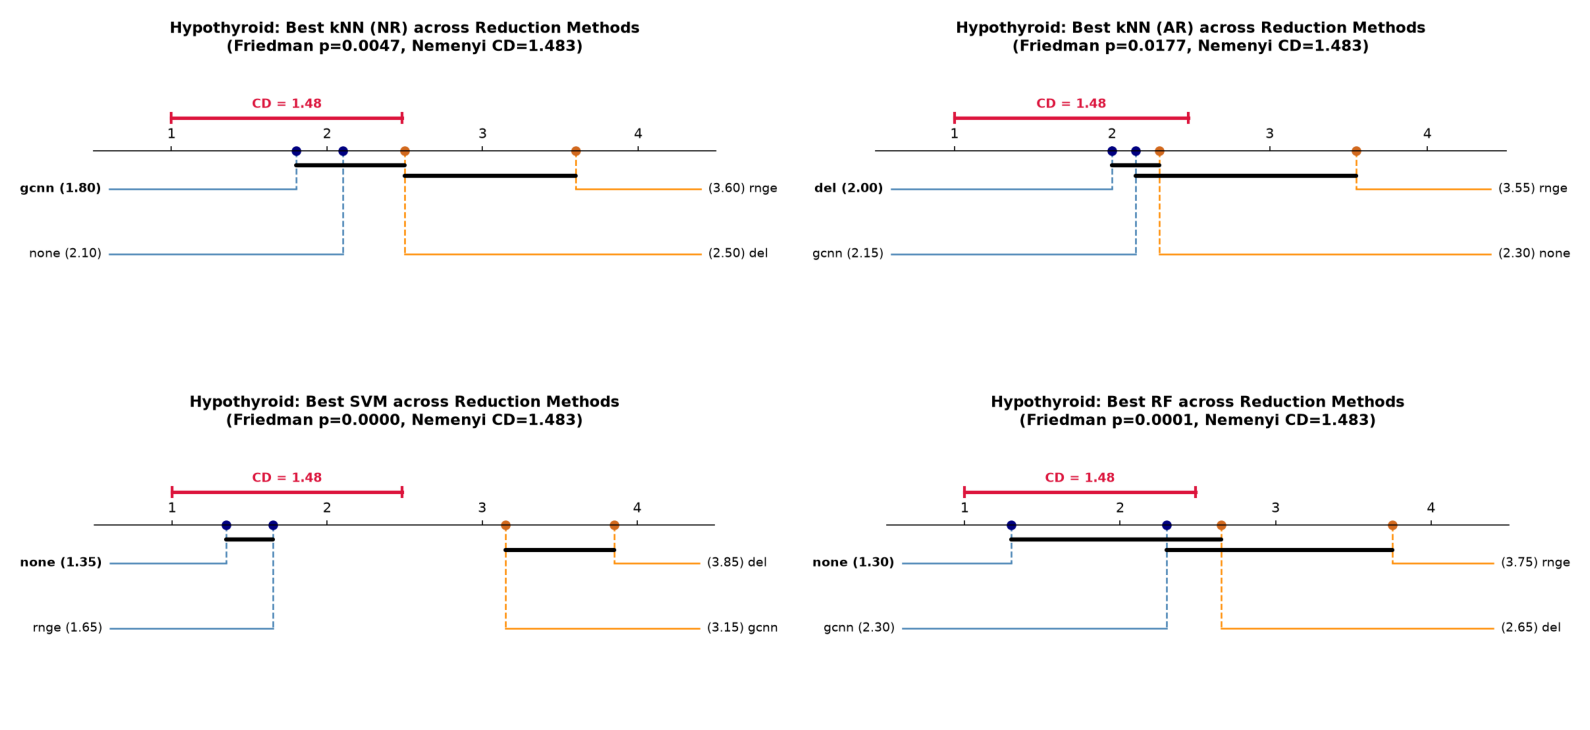

In [12]:
for algo_key, algo_label in [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]:
    df_fr_hypo = pd.read_csv(REDUCTION_DIR / f'hypothyroid_stats_{algo_key}_reduction.csv')
    print(f'=== Hypothyroid Friedman Rankings across Reduction Methods: {algo_label} ===')
    display(df_fr_hypo)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, (algo_key, algo_label) in zip(axes.flat, [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]):
    img = plt.imread(REDUCTION_DIR / f'hypothyroid_cd_{algo_key}_reduction.png')
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.show()


### 2.2 Hypothyroid: Friedman Rankings & Critical Difference (CD) Diagrams per Classifier


=== Hypothyroid Friedman Rankings across Reduction Methods: Best kNN (NR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,gcnn,1.8,0.968454,0.007109,0.0,True,True
1,none,2.1,0.966078,0.010843,0.3,True,True
2,del,2.5,0.966605,0.008270,0.7,True,True
3,rnge,3.6,0.960772,0.009386,1.8,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best kNN (AR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,del,2.00,0.969524,0.007372,0.00,True,True
1,gcnn,2.15,0.967664,0.006673,0.15,True,True
2,none,2.30,0.966343,0.010646,0.30,True,True
3,rnge,3.55,0.960773,0.009629,1.55,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best SVM ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.35,0.975100,0.010715,0.0,True,True
1,rnge,1.65,0.971918,0.011209,0.3,True,True
2,gcnn,3.15,0.934537,0.018204,1.8,False,False
3,del,3.85,0.907218,0.025199,2.5,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best RF ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.30,0.995763,0.003103,0.00,True,True
1,gcnn,2.30,0.993374,0.003592,1.00,True,True
2,del,2.65,0.992320,0.005054,1.35,True,True
3,rnge,3.75,0.988076,0.006509,2.45,False,False


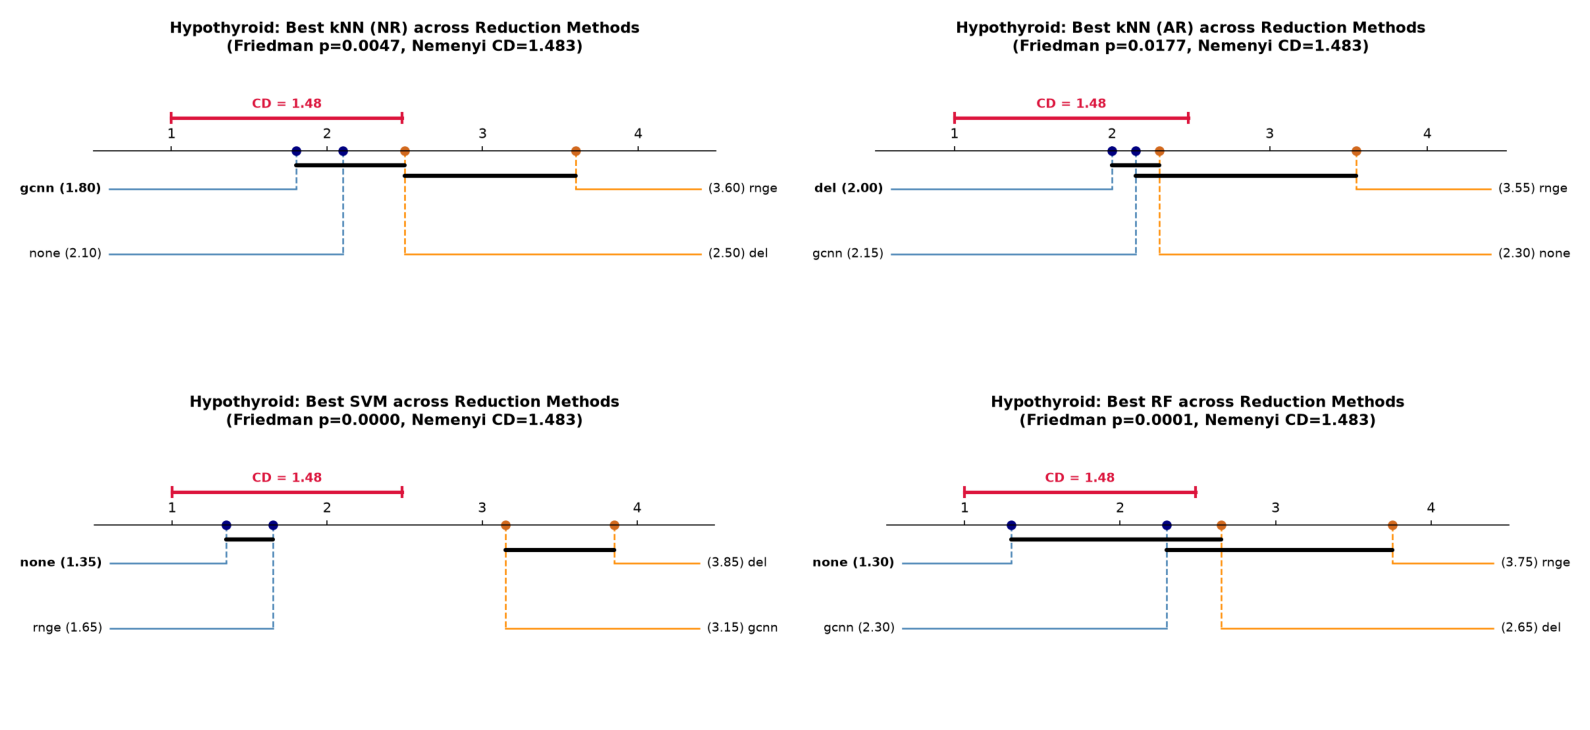

In [13]:
for algo_key, algo_label in [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]:
    df_fr_hypo = pd.read_csv(REDUCTION_DIR / f'hypothyroid_stats_{algo_key}_reduction.csv')
    print(f'=== Hypothyroid Friedman Rankings across Reduction Methods: {algo_label} ===')
    display(df_fr_hypo)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, (algo_key, algo_label) in zip(axes.flat, [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]):
    img = plt.imread(REDUCTION_DIR / f'hypothyroid_cd_{algo_key}_reduction.png')
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.show()


### 2.2 Hypothyroid: Friedman Rankings & Critical Difference (CD) Diagrams per Classifier


=== Hypothyroid Friedman Rankings across Reduction Methods: Best kNN (NR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,gcnn,1.8,0.968454,0.007109,0.0,True,True
1,none,2.1,0.966078,0.010843,0.3,True,True
2,del,2.5,0.966605,0.008270,0.7,True,True
3,rnge,3.6,0.960772,0.009386,1.8,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best kNN (AR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,del,2.00,0.969524,0.007372,0.00,True,True
1,gcnn,2.15,0.967664,0.006673,0.15,True,True
2,none,2.30,0.966343,0.010646,0.30,True,True
3,rnge,3.55,0.960773,0.009629,1.55,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best SVM ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.35,0.975100,0.010715,0.0,True,True
1,rnge,1.65,0.971918,0.011209,0.3,True,True
2,gcnn,3.15,0.934537,0.018204,1.8,False,False
3,del,3.85,0.907218,0.025199,2.5,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best RF ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.30,0.995763,0.003103,0.00,True,True
1,gcnn,2.30,0.993374,0.003592,1.00,True,True
2,del,2.65,0.992320,0.005054,1.35,True,True
3,rnge,3.75,0.988076,0.006509,2.45,False,False


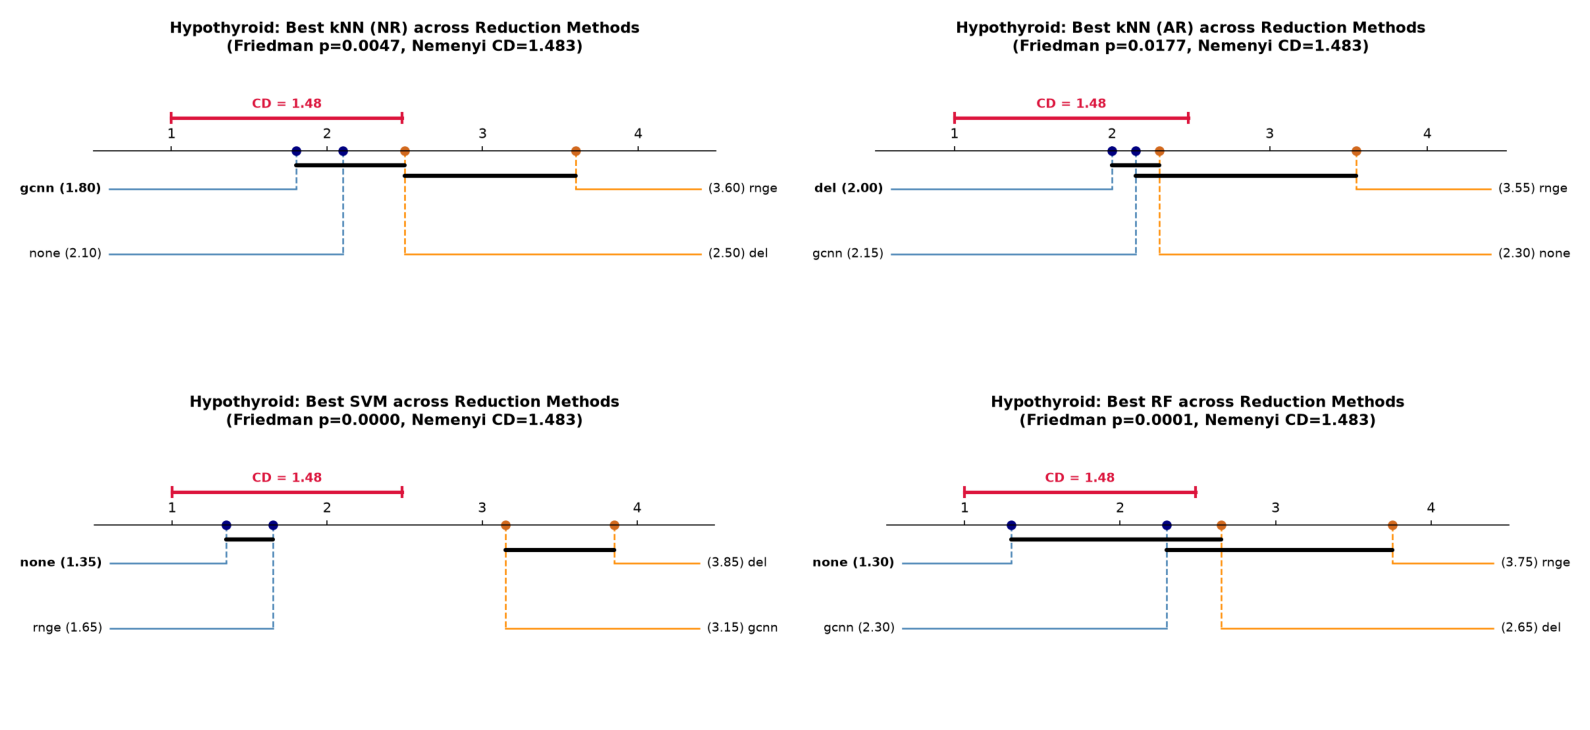

In [14]:
for algo_key, algo_label in [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]:
    df_fr_hypo = pd.read_csv(REDUCTION_DIR / f'hypothyroid_stats_{algo_key}_reduction.csv')
    print(f'=== Hypothyroid Friedman Rankings across Reduction Methods: {algo_label} ===')
    display(df_fr_hypo)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, (algo_key, algo_label) in zip(axes.flat, [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]):
    img = plt.imread(REDUCTION_DIR / f'hypothyroid_cd_{algo_key}_reduction.png')
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.show()


### 2.2 Hypothyroid: Friedman Rankings & Critical Difference (CD) Diagrams per Classifier


=== Hypothyroid Friedman Rankings across Reduction Methods: Best kNN (NR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,gcnn,1.8,0.968454,0.007109,0.0,True,True
1,none,2.1,0.966078,0.010843,0.3,True,True
2,del,2.5,0.966605,0.008270,0.7,True,True
3,rnge,3.6,0.960772,0.009386,1.8,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best kNN (AR) ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,del,2.00,0.969524,0.007372,0.00,True,True
1,gcnn,2.15,0.967664,0.006673,0.15,True,True
2,none,2.30,0.966343,0.010646,0.30,True,True
3,rnge,3.55,0.960773,0.009629,1.55,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best SVM ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.35,0.975100,0.010715,0.0,True,True
1,rnge,1.65,0.971918,0.011209,0.3,True,True
2,gcnn,3.15,0.934537,0.018204,1.8,False,False
3,del,3.85,0.907218,0.025199,2.5,False,False


=== Hypothyroid Friedman Rankings across Reduction Methods: Best RF ===


,model,average_rank,mean_score,std_score,rank_diff_from_best,within_nemenyi_cd,within_bonferroni_cd
0,none,1.30,0.995763,0.003103,0.00,True,True
1,gcnn,2.30,0.993374,0.003592,1.00,True,True
2,del,2.65,0.992320,0.005054,1.35,True,True
3,rnge,3.75,0.988076,0.006509,2.45,False,False


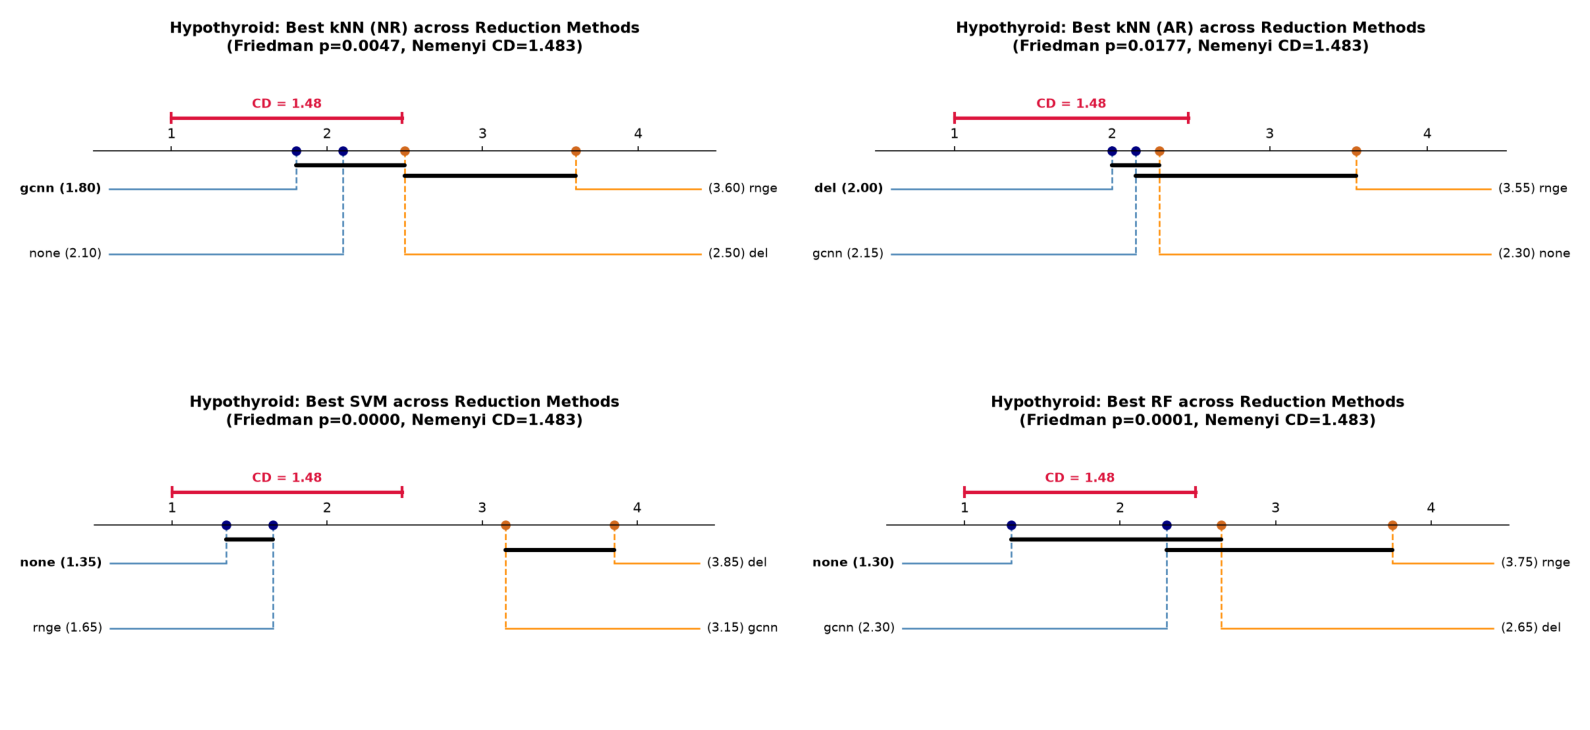

In [15]:
for algo_key, algo_label in [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]:
    df_fr_hypo = pd.read_csv(REDUCTION_DIR / f'hypothyroid_stats_{algo_key}_reduction.csv')
    print(f'=== Hypothyroid Friedman Rankings across Reduction Methods: {algo_label} ===')
    display(df_fr_hypo)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for ax, (algo_key, algo_label) in zip(axes.flat, [
    ('best_knn_nr', 'Best kNN (NR)'),
    ('best_knn_ar', 'Best kNN (AR)'),
    ('best_svm', 'Best SVM'),
    ('best_rf', 'Best RF'),
]):
    img = plt.imread(REDUCTION_DIR / f'hypothyroid_cd_{algo_key}_reduction.png')
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.show()


## 3. Visual Analysis: 2x2 Impact Plots
Displays the empirical 2x2 comparison plots:
1. **Classification Accuracy (%)** by reduction method across all algorithms.
2. **Training Storage Retained (%)** across GCNN, RNGE, and DEL.
3. **kNN Prediction Time (ms)** before vs after reduction.
4. **Instance Reduction Preprocessing Time (s)**.


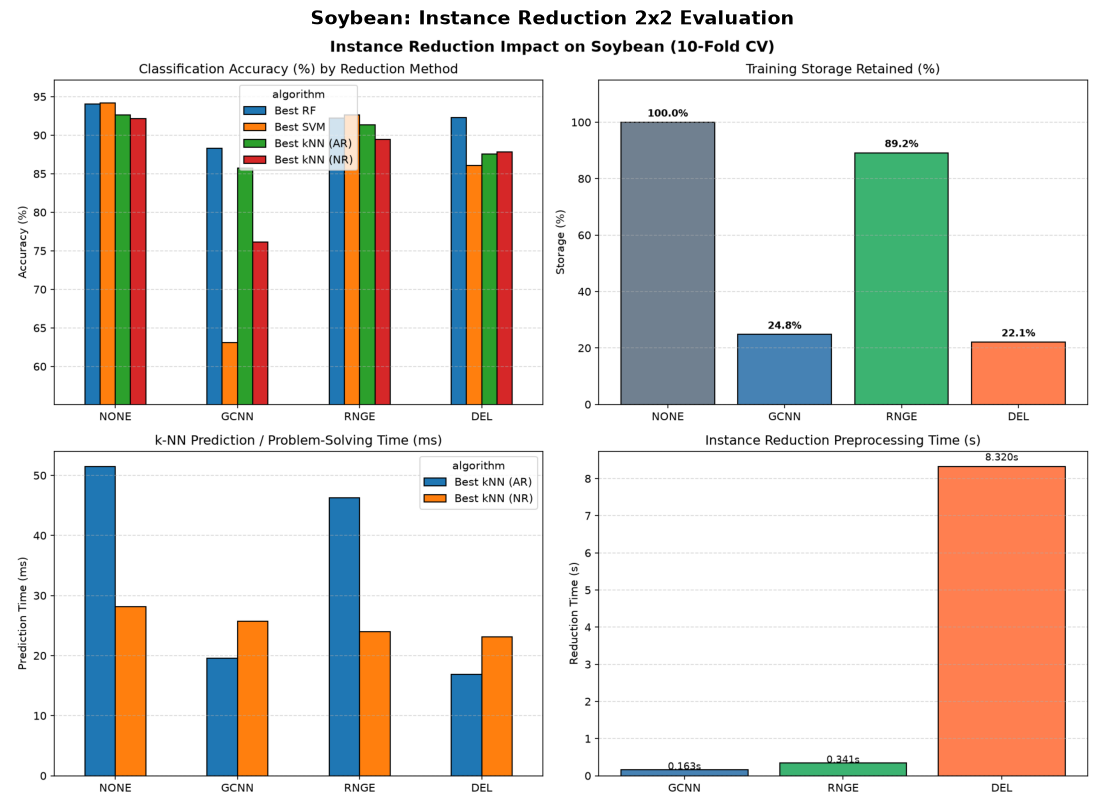

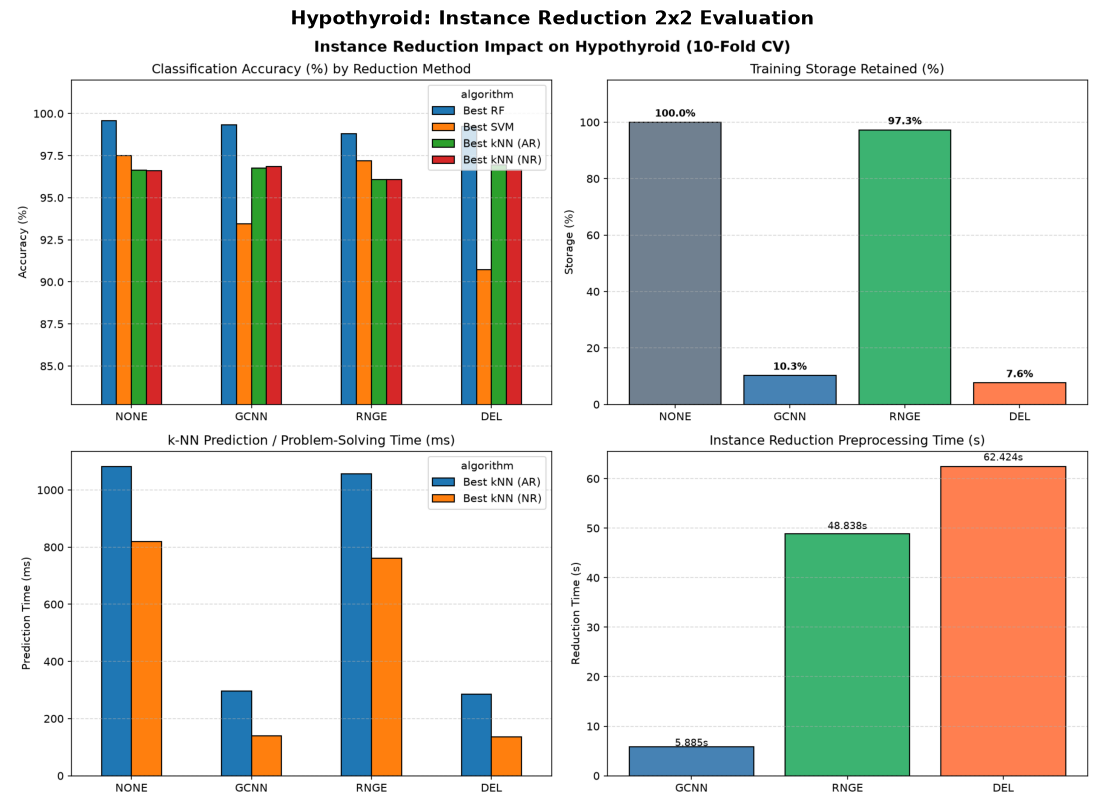

In [16]:
# Display generated plots dynamically
img_soy = plt.imread(REDUCTION_DIR / "soybean_reduction_analysis.png")
fig, ax = plt.subplots(figsize=(14, 10))
ax.imshow(img_soy)
ax.axis("off")
ax.set_title("Soybean: Instance Reduction 2x2 Evaluation", fontsize=14, fontweight="bold")
plt.show()

img_hypo = plt.imread(REDUCTION_DIR / "hypothyroid_reduction_analysis.png")
fig, ax = plt.subplots(figsize=(14, 10))
ax.imshow(img_hypo)
ax.axis("off")
ax.set_title("Hypothyroid: Instance Reduction 2x2 Evaluation", fontsize=14, fontweight="bold")
plt.show()


## 4. Key Methodological Takeaways

1. **Storage Compression**:
   - Condensation and decremental methods eliminate redundant internal instances while preserving boundary points.
   - Graph-based editing focuses on eliminating label noise and smoothing class boundaries.
2. **Inference Latency & Efficiency**:
   - Reduction directly accelerates lazy nearest-neighbour problem-solving time by reducing search space size.
   - For eager classifiers (SVM, Random Forest), training on reduced prototype subsets accelerates model training time.
